# PACKAGES

In [ ]:
from kloppy import metrica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch
from scipy.spatial import Delaunay
import matplotlib.pyplot as plt

# LOADING DATA

In [2]:


# Load and merge the Home and Away tracking CSVs
dataset = metrica.load_tracking_csv(
    home_data="Game1trackhome.csv",
    away_data="Game1trackaway.csv",
    coordinates="metrica"  # Keeps pitch coordinates normalized between 0 and 1
)

# Convert to a single combined Pandas DataFrame
df_tracking = dataset.to_df(engine="pandas")

print(df_tracking.shape)
df_tracking.head()

(145006, 121)


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,home_25_x,...,away_13_d,away_13_s,home_28_x,home_28_y,home_28_d,home_28_s,away_14_x,away_14_y,away_14_d,away_14_s
0,1,0 days 00:00:00.040000,1,None,None,0.45472,0.61291,None,None,0.90509,...,None,None,NaN,NaN,None,None,NaN,NaN,None,None
1,1,0 days 00:00:00.080000,2,None,None,0.49645,0.59344,None,None,0.90494,...,None,None,NaN,NaN,None,None,NaN,NaN,None,None
2,1,0 days 00:00:00.120000,3,None,None,0.53716,0.57444,None,None,0.90434,...,None,None,NaN,NaN,None,None,NaN,NaN,None,None
3,1,0 days 00:00:00.160000,4,None,None,0.55346,0.57769,None,None,0.90377,...,None,None,NaN,NaN,None,None,NaN,NaN,None,None
4,1,0 days 00:00:00.200000,5,None,None,0.55512,0.59430,None,None,0.90324,...,None,None,NaN,NaN,None,None,NaN,NaN,None,None


# CALCULATION OF AVERGAE SPEED OF EACH PLAYER

In [3]:
# 1. Pitch dimensions in meters (standard FIFA pitch)
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
FRAME_RATE = 25.0  # 25 Hz -> 0.04 seconds per frame
DT = 1.0 / FRAME_RATE

# 2. Extract unique player prefixes (e.g., 'home_25', 'away_13')
player_ids = sorted(list({
    col[:-2] for col in df_tracking.columns 
    if (col.startswith("home_") or col.startswith("away_")) and col.endswith("_x")
}))

results = []

for pid in player_ids:
    # Convert normalized (0-1) coordinates to meters
    x = df_tracking[f"{pid}_x"] * PITCH_LENGTH
    y = df_tracking[f"{pid}_y"] * PITCH_WIDTH
    
    # Compute frame-to-frame difference grouped by period_id 
    # (prevents a false teleportation spike at halftime!)
    dx = x.groupby(df_tracking["period_id"]).diff()
    dy = y.groupby(df_tracking["period_id"]).diff()
    
    # Instantaneous speed (m/s)
    raw_speed = np.sqrt(dx**2 + dy**2) / DT
    
    # Smooth optical tracking noise (7-frame moving average) and cap impossible spikes (>12 m/s)
    smooth_speed = raw_speed.rolling(window=7, min_periods=1, center=True).mean()
    smooth_speed = smooth_speed.where(smooth_speed <= 12.0, np.nan)
    
    # Calculate metrics only for frames when the player was actually on the pitch
    minutes_played = smooth_speed.notna().sum() * DT / 60.0
    avg_speed_ms = smooth_speed.mean()
    avg_speed_kmh = avg_speed_ms * 3.6
    total_distance_km = (smooth_speed.sum() * DT) / 1000.0
    
    results.append({
        "player": pid,
        "team": pid.split("_")[0].capitalize(),
        "minutes_played": round(minutes_played, 1),
        "avg_speed_m_s": round(avg_speed_ms, 2),
        "avg_speed_km_h": round(avg_speed_kmh, 2),
        "total_distance_km": round(total_distance_km, 2)
    })

speed_summary = pd.DataFrame(results).sort_values(by="avg_speed_m_s", ascending=False)
speed_summary

,player,team,minutes_played,avg_speed_m_s,avg_speed_km_h,total_distance_km
27,home_28,Home,17.1,2.08,7.48,2.13
18,home_19,Home,79.6,2.08,7.49,9.94
5,away_14,Away,15.7,2.06,7.43,1.95
17,home_18,Home,96.7,1.95,7.01,11.29
12,away_8,Away,96.6,1.94,7.00,11.27
10,away_6,Away,73.9,1.93,6.94,8.55
9,away_5,Away,96.7,1.92,6.90,11.12
20,home_21,Home,96.7,1.90,6.83,11.00
16,home_17,Home,96.7,1.89,6.82,10.98
26,home_27,Home,25.4,1.89,6.79,2.88


# TOP SPEED

In [4]:
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
FRAME_RATE = 25.0
DT = 1.0 / FRAME_RATE

SPRINT_THRESHOLD = 7.0   # m/s (25.2 km/h) - standard football sprint threshold
MAX_DURATION_SEC = 2.0   # Maximum sprint duration in seconds
MAX_FRAMES = int(MAX_DURATION_SEC * FRAME_RATE)  # 50 frames at 25 Hz

player_ids = sorted(list({
    col[:-2] for col in df_tracking.columns 
    if (col.startswith("home_") or col.startswith("away_")) and col.endswith("_x")
}))

top_speed_results = []

for pid in player_ids:
    x = df_tracking[f"{pid}_x"] * PITCH_LENGTH
    y = df_tracking[f"{pid}_y"] * PITCH_WIDTH
    
    # Frame-to-frame displacement within each period
    dx = x.groupby(df_tracking["period_id"]).diff()
    dy = y.groupby(df_tracking["period_id"]).diff()
    
    # Raw speed and smoothed speed (removes single-frame camera jitter)
    raw_speed = np.sqrt(dx**2 + dy**2) / DT
    smooth_speed = raw_speed.rolling(window=7, min_periods=1, center=True).mean()
    smooth_speed = smooth_speed.where(smooth_speed <= 12.0, np.nan)
    
    # Identify frames where player is sprinting (>= 7.0 m/s)
    is_sprint = smooth_speed >= SPRINT_THRESHOLD
    
    # Group consecutive sprint frames into distinct sprint bouts
    sprint_bout_id = (is_sprint != is_sprint.shift()).cumsum()
    
    # Calculate duration (in frames) of each consecutive bout
    bout_lengths = is_sprint.groupby(sprint_bout_id).transform("sum")
    
    # Keep ONLY sprint frames belonging to bouts lasting LESS than 2 seconds (< 50 frames)
    # Note: bout_lengths >= 3 filters out 1-2 frame optical noise spikes (~0.08s)
    short_sprint_speeds = smooth_speed.where(is_sprint & (bout_lengths < MAX_FRAMES) & (bout_lengths >= 3))
    
    peak_ms = short_sprint_speeds.max()
    peak_kmh = peak_ms * 3.6 if pd.notna(peak_ms) else np.nan
    num_short_sprints = sprint_bout_id[is_sprint & (bout_lengths < MAX_FRAMES) & (bout_lengths >= 3)].nunique()
    
    top_speed_results.append({
        "player": pid,
        "team": pid.split("_")[0].capitalize(),
        "short_sprint_count": num_short_sprints,
        "top_speed_m_s": round(peak_ms, 2) if pd.notna(peak_ms) else None,
        "top_speed_km_h": round(peak_kmh, 2) if pd.notna(peak_kmh) else None
    })

top_speeds_df = pd.DataFrame(top_speed_results).sort_values(by="top_speed_km_h", ascending=False)
top_speeds_df

,player,team,short_sprint_count,top_speed_m_s,top_speed_km_h
25,home_26,Home,10,11.95,43.02
1,away_10,Away,14,11.93,42.96
6,away_2,Away,26,11.93,42.93
12,away_8,Away,30,11.92,42.91
23,home_24,Home,18,11.90,42.83
18,home_19,Home,4,11.80,42.48
13,away_9,Away,23,11.77,42.38
17,home_18,Home,16,11.77,42.36
21,home_22,Home,16,11.74,42.28
7,away_3,Away,13,11.70,42.12


# AVERAGE POSTION 

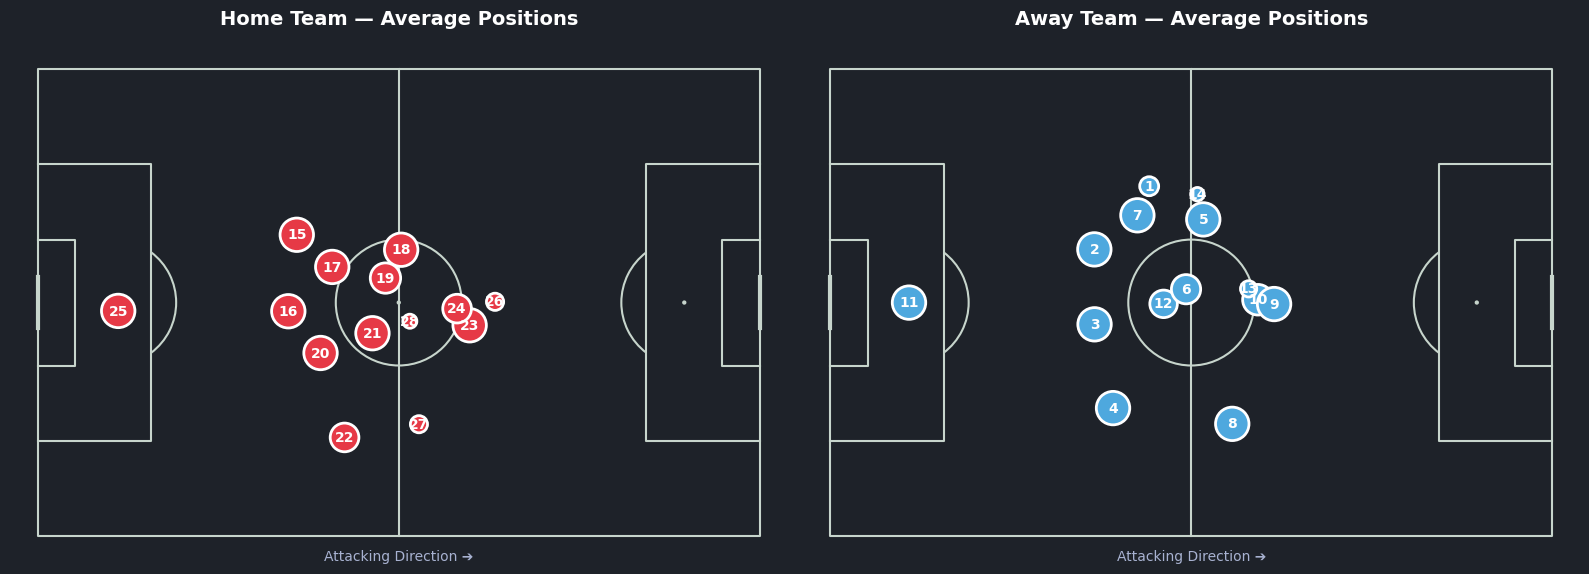

In [5]:

# 1. Make a copy of tracking coordinates to normalize playing direction
df_norm = df_tracking.copy()

# Determine which team starts on the left (x < 0.5) vs right (x > 0.5) in Period 1
p1 = df_norm[df_norm["period_id"] == 1]
home_x_cols = [c for c in df_norm.columns if c.startswith("home_") and c.endswith("_x")]
away_x_cols = [c for c in df_norm.columns if c.startswith("away_") and c.endswith("_x")]

home_p1_mean_x = p1[home_x_cols].mean().mean()

# Flip coordinates so BOTH teams always attack Left -> Right in BOTH periods
for prefix, starts_on_left in [("home_", home_p1_mean_x < 0.5), ("away_", home_p1_mean_x >= 0.5)]:
    x_cols = [c for c in df_norm.columns if c.startswith(prefix) and c.endswith("_x")]
    y_cols = [c for c in df_norm.columns if c.startswith(prefix) and c.endswith("_y")]
    
    # Period to flip: if team starts on left, flip Period 2; if team starts on right, flip Period 1
    flip_period = 2 if starts_on_left else 1
    mask = df_norm["period_id"] == flip_period
    
    df_norm.loc[mask, x_cols] = 1.0 - df_norm.loc[mask, x_cols]
    df_norm.loc[mask, y_cols] = 1.0 - df_norm.loc[mask, y_cols]

# 2. Compute average (x, y) and minutes played for each player
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
DT = 1.0 / 25.0

avg_positions = []
player_ids = sorted({
    col[:-2] for col in df_norm.columns 
    if (col.startswith("home_") or col.startswith("away_")) and col.endswith("_x")
})

for pid in player_ids:
    valid_frames = df_norm[f"{pid}_x"].notna().sum()
    minutes = valid_frames * DT / 60.0
    
    # Filter out brief late-game substitutes (< 15 mins) so the 11-man shape stays clean
    if minutes >= 15.0:
        avg_positions.append({
            "player": pid,
            "team": pid.split("_")[0],
            "jersey": pid.split("_")[1],
            "minutes": round(minutes, 1),
            "avg_x": df_norm[f"{pid}_x"].mean() * PITCH_LENGTH,
            # Invert Y because Metrica uses 0=top, 1=bottom while mplsoccer uses 0=bottom, 68=top
            "avg_y": (1.0 - df_norm[f"{pid}_y"].mean()) * PITCH_WIDTH
        })

pos_df = pd.DataFrame(avg_positions)

# 3. Plot Home and Away teams on separate side-by-side pitches
pitch = Pitch(
    pitch_type="custom",
    pitch_length=PITCH_LENGTH,
    pitch_width=PITCH_WIDTH,
    pitch_color="#1e2229",
    line_color="#c7d5cc",
    linewidth=1.5
)

fig, axs = pitch.draw(nrows=1, ncols=2, figsize=(16, 6.5))
fig.patch.set_facecolor("#1e2229")

team_configs = [
    ("home", "Home Team — Average Positions", "#e63946", axs[0]),
    ("away", "Away Team — Average Positions", "#4ea8de", axs[1])
]

for team_key, title, color, ax in team_configs:
    team_data = pos_df[pos_df["team"] == team_key]
    
    # Plot player nodes (marker size scaled slightly by minutes played)
    pitch.scatter(
        team_data["avg_x"],
        team_data["avg_y"],
        s=team_data["minutes"] * 6,
        color=color,
        edgecolors="white",
        linewidth=2,
        zorder=3,
        ax=ax
    )
    
    # Annotate jersey numbers inside each circle
    for _, row in team_data.iterrows():
        ax.text(
            row["avg_x"],
            row["avg_y"],
            row["jersey"],
            color="white",
            fontsize=10,
            fontweight="bold",
            ha="center",
            va="center",
            zorder=4
        )
        
    ax.set_title(title, color="white", fontsize=14, fontweight="bold", pad=12)
    ax.text(
        PITCH_LENGTH / 2, -3.5, "Attacking Direction ➔",
        color="#a8b2d1", fontsize=10, ha="center"
    )

plt.tight_layout()
plt.show()

# ACTIVE TRIANGLES USING DELANEY TRIANGULATION

In [7]:
# ==========================================
# 1. Setup Pitch Scaling & Identify Outfield Players
# ==========================================
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0

# Load events CSV to isolate in-possession frames
events_df = pd.read_csv("Game1event.csv")

def get_possession_mask(df_track, events, team="Home"):
    mask = np.zeros(len(df_track), dtype=bool)
    team_events = events[events["Team"] == team]
    frame_to_idx = pd.Series(df_track.index.values, index=df_track["frame_id"]).to_dict()
    
    for _, row in team_events.iterrows():
        sf, ef = row["Start Frame"], row["End Frame"]
        if sf in frame_to_idx and ef in frame_to_idx:
            mask[frame_to_idx[sf] : frame_to_idx[ef] + 1] = True
    return mask

home_poss_mask = get_possession_mask(df_tracking, events_df, team="Home")

# Find all Home players and exclude the Goalkeeper (lowest average X distance from own goal)
home_players = sorted({
    col[:-2] for col in df_tracking.columns 
    if col.startswith("home_") and col.endswith("_x")
})

# Identify GK in Period 1 (furthest back along X-axis)
p1_means = {pid: df_tracking.loc[df_tracking["period_id"] == 1, f"{pid}_x"].mean() for pid in home_players}
# Check whether Home starts on left (<0.5) or right (>0.5)
starts_left = np.nanmean(list(p1_means.values())) < 0.5
gk_id = min(p1_means, key=p1_means.get) if starts_left else max(p1_means, key=p1_means.get)

outfield_home = [p for p in home_players if p != gk_id]
print(f"Excluded Goalkeeper: {gk_id} | Outfield pool: {len(outfield_home)} players")

# ==========================================
# 2. Frame-by-Frame Delaunay Triangulation & Active Triangle Tracking
# ==========================================
# Downsample to 5Hz (step=5) so transitions reflect tactical shifts rather than 40ms jitter
df_5hz = df_tracking[home_poss_mask].iloc[::5].copy().reset_index(drop=True)

active_triangles = []
valid_frames_data = []

for idx, row in df_5hz.iterrows():
    # Get coordinates (in meters) for the 10 active outfield players on the pitch
    coords = []
    active_pids = []
    for pid in outfield_home:
        px, py = row[f"{pid}_x"], row[f"{pid}_y"]
        if pd.notna(px) and pd.notna(py):
            coords.append([px * PITCH_LENGTH, py * PITCH_WIDTH])
            active_pids.append(pid)
            
    # Need at least 4 outfield players to form a valid 2D Delaunay triangulation
    if len(coords) < 4 or pd.isna(row["ball_x"]) or pd.isna(row["ball_y"]):
        active_triangles.append(None)
        continue
        
    pts = np.array(coords)
    ball_pt = np.array([row["ball_x"] * PITCH_LENGTH, row["ball_y"] * PITCH_WIDTH])
    
    # Compute Delaunay Triangulation
    tri = Delaunay(pts)
    
    # Method 1: Find the exact Delaunay triangle enclosing the ball
    simplex_idx = tri.find_simplex(ball_pt)
    
    if simplex_idx != -1:
        # Sort the 3 player IDs so ('home_4', 'home_6', 'home_8') is canonical
        triangle_players = tuple(sorted([active_pids[i] for i in tri.simplices[simplex_idx]]))
        active_triangles.append(triangle_players)
        valid_frames_data.append((idx, pts, tri, simplex_idx, ball_pt, triangle_players))
    else:
        # Ball is outside the convex hull of outfield players (e.g., wide touchline or back to GK)
        active_triangles.append("OUTSIDE_HULL")

# ==========================================
# 3. Compute Shannon Entropy of Triangle Transitions
# ==========================================
# Filter consecutive valid states within the same period
transitions = []
for i in range(len(active_triangles) - 1):
    t_curr = active_triangles[i]
    t_next = active_triangles[i + 1]
    same_period = df_5hz.loc[i, "period_id"] == df_5hz.loc[i + 1, "period_id"]
    
    if same_period and t_curr not in (None, "OUTSIDE_HULL") and t_next not in (None, "OUTSIDE_HULL"):
        # Optional: Ignore self-transitions (t_curr == t_next) to measure purely structural *changes*
        if t_curr != t_next:
            transitions.append((t_curr, t_next))

trans_df = pd.DataFrame(transitions, columns=["From_Triangle", "To_Triangle"])

# Joint probability P(T_i, T_j) and Conditional probability P(T_j | T_i)
joint_counts = trans_df.value_counts()
joint_probs = joint_counts / joint_counts.sum()

from_counts = trans_df["From_Triangle"].value_counts()
cond_probs = joint_counts / joint_counts.index.get_level_values(0).map(from_counts)

# Shannon Transition Entropy (in bits)
transition_entropy = -np.sum(joint_probs * np.log2(cond_probs))

# Normalized Entropy (0 to 1 scale, dividing by log2 of unique triangles observed)
unique_triangles = pd.Series([t for t in active_triangles if t not in (None, "OUTSIDE_HULL")]).nunique()
norm_entropy = transition_entropy / np.log2(unique_triangles) if unique_triangles > 1 else 0.0

print(f"\n--- Topological Passing Triangle Summary (Home In-Possession) ---")
print(f"Unique Active Triangles Observed: {unique_triangles}")
print(f"Triangle Transition Entropy:      {transition_entropy:.3f} bits")
print(f"Normalized Transition Entropy:    {norm_entropy:.3f} (0 = rigid structure, 1 = maximum fluidity)")

print("\nTop 10 Most Frequent Ball-Enclosing Passing Triangles:")
tri_counts = pd.Series([t for t in active_triangles if t not in (None, "OUTSIDE_HULL")]).value_counts()
print(tri_counts.head(10))

Excluded Goalkeeper: home_25 | Outfield pool: 13 players

--- Topological Passing Triangle Summary (Home In-Possession) ---
Unique Active Triangles Observed: 152
Triangle Transition Entropy:      2.195 bits
Normalized Transition Entropy:    0.303 (0 = rigid structure, 1 = maximum fluidity)

Top 10 Most Frequent Ball-Enclosing Passing Triangles:
(home_18, home_21, home_24)    56
(home_21, home_23, home_24)    53
(home_19, home_21, home_23)    50
(home_18, home_23, home_24)    45
(home_19, home_21, home_24)    37
(home_18, home_21, home_23)    37
(home_20, home_21, home_22)    35
(home_19, home_20, home_21)    33
(home_18, home_19, home_24)    33
(home_16, home_17, home_20)    32
Name: count, dtype: int64


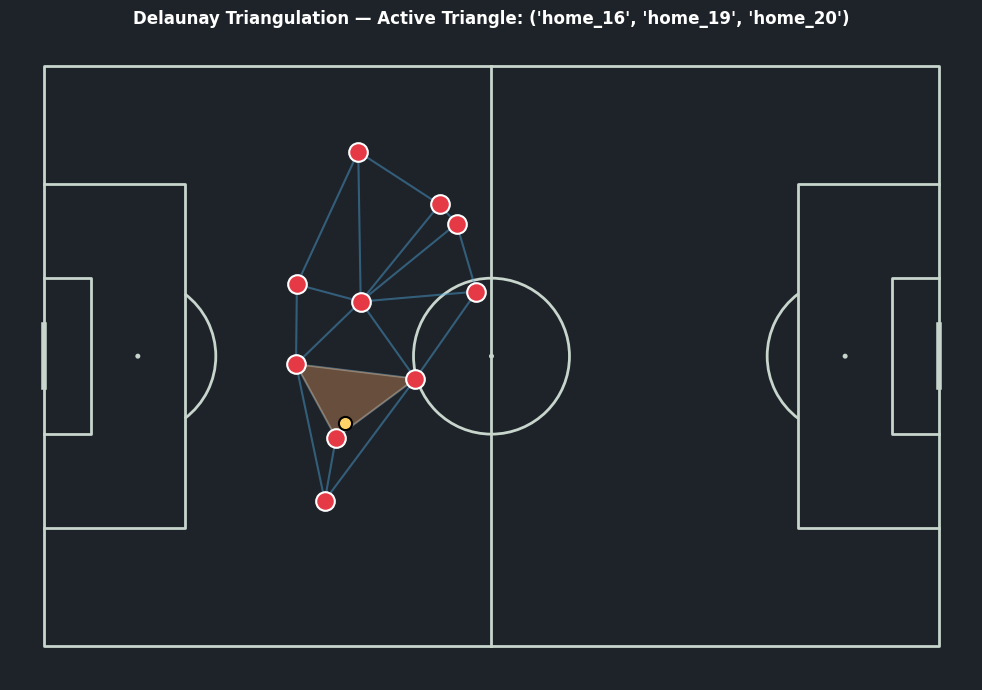

In [9]:
# Pick a sample valid frame from the list we stored
sample_idx, pts, tri, active_simplex, ball_pt, tri_names = valid_frames_data[1500]

pitch = Pitch(pitch_type="custom", pitch_length=PITCH_LENGTH, pitch_width=PITCH_WIDTH,
              pitch_color="#1e2229", line_color="#c7d5cc")
fig, ax = pitch.draw(figsize=(11, 7))
fig.patch.set_facecolor("#1e2229")

# 1. Draw all Delaunay triangles in subtle cyan
ax.triplot(pts[:, 0], PITCH_WIDTH - pts[:, 1], tri.simplices, color="#4ea8de", alpha=0.45, lw=1.5, zorder=2)

# 2. Highlight the active ball-enclosing triangle in bright gold
active_verts = pts[tri.simplices[active_simplex]]
ax.fill(active_verts[:, 0], PITCH_WIDTH - active_verts[:, 1], color="#f4a261", alpha=0.35, zorder=2)

# 3. Plot the 10 outfield players and the ball
pitch.scatter(pts[:, 0], PITCH_WIDTH - pts[:, 1], s=180, color="#e63946", edgecolors="white", lw=1.5, zorder=3, ax=ax)
pitch.scatter(ball_pt[0], PITCH_WIDTH - ball_pt[1], s=90, color="#ffd166", edgecolors="black", lw=1.5, zorder=4, ax=ax)

ax.set_title(f"Delaunay Triangulation — Active Triangle: {tri_names}", color="white", fontsize=12, fontweight="bold")
plt.show()

# ANIMATION TRY

Animating 60s before HOME goal at Frame 2289 (Period 1)


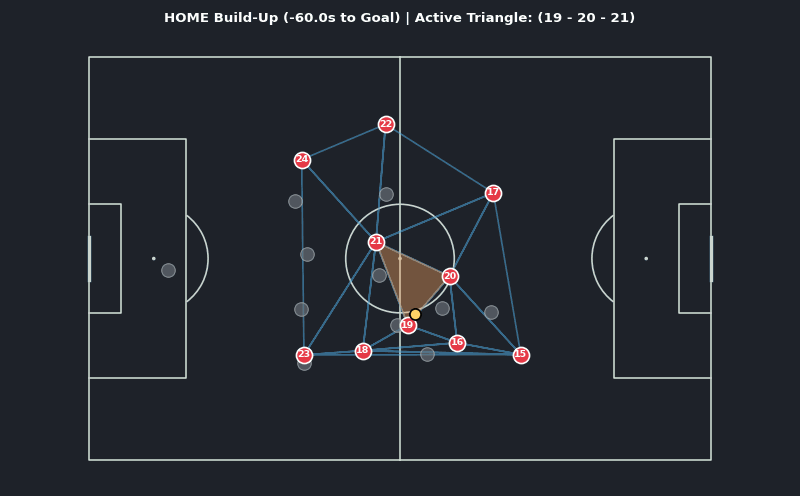

In [14]:
import numpy as np
import pandas as pd
from scipy.spatial import Delaunay
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image
from mplsoccer import Pitch

mpl.rcParams['animation.embed_limit'] = 50.0

PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
FRAME_RATE = 25

# ==========================================
# 1. Automatically Find a Goal in events_df
# ==========================================
events_df = pd.read_csv("Game1event.csv")

goals = events_df[
    (events_df["Type"] == "SHOT") & 
    (events_df["Subtype"].str.contains("GOAL", case=False, na=False))
]

if len(goals) == 0:
    raise ValueError("No goals found in events_df! Check events_df['Subtype'].unique().")

goal_event = goals.iloc[0]
goal_frame = int(goal_event["Start Frame"])
scoring_team = goal_event["Team"].lower()
defending_team = "away" if scoring_team == "home" else "home"
period_id = int(goal_event["Period"])

print(f"Animating 60s before {scoring_team.upper()} goal at Frame {goal_frame} (Period {period_id})")

# ==========================================
# 2. Extract the 60-Second Window (~8.3 fps)
# ==========================================
start_frame = max(1, goal_frame - (60 * FRAME_RATE))
window_df = df_tracking[
    (df_tracking["period_id"] == period_id) &
    (df_tracking["frame_id"] >= start_frame) &
    (df_tracking["frame_id"] <= goal_frame + 25)
].iloc[::3].copy().reset_index(drop=True)

team_players = sorted({
    col[:-2] for col in df_tracking.columns 
    if col.startswith(f"{scoring_team}_") and col.endswith("_x")
})
def_players = sorted({
    col[:-2] for col in df_tracking.columns 
    if col.startswith(f"{defending_team}_") and col.endswith("_x")
})

p_means = {pid: window_df[f"{pid}_x"].mean() for pid in team_players if window_df[f"{pid}_x"].notna().any()}
gk_id = min(p_means, key=lambda k: min(p_means[k], 1.0 - p_means[k]))
outfield_players = [p for p in team_players if p != gk_id]

# ==========================================
# 3. Set Up Pitch Canvas & Animation Artists
# ==========================================
pitch = Pitch(
    pitch_type="custom", pitch_length=PITCH_LENGTH, pitch_width=PITCH_WIDTH,
    pitch_color="#1e2229", line_color="#c7d5cc", linewidth=1.5
)
fig, ax = pitch.draw(figsize=(10, 6.2))
fig.set_dpi(80)
fig.patch.set_facecolor("#1e2229")

tri_lines = ax.plot([], [], color="#4ea8de", alpha=0.55, lw=1.5, zorder=2)[0]
active_poly = ax.fill([], [], color="#f4a261", alpha=0.40, zorder=2)[0]
att_scatter = ax.scatter([], [], s=210, color="#e63946", edgecolors="white", lw=1.5, zorder=4)
def_scatter = ax.scatter([], [], s=150, color="#6c757d", edgecolors="#adb5bd", alpha=0.65, lw=1, zorder=3)
ball_scatter = ax.scatter([], [], s=100, color="#ffd166", edgecolors="black", lw=1.5, zorder=5)

jersey_texts = [
    ax.text(0, 0, "", color="white", fontsize=8.5, fontweight="bold", ha="center", va="center", zorder=5)
    for _ in range(11)
]
title_text = ax.set_title("", color="white", fontsize=12, fontweight="bold", pad=10)

# ==========================================
# 4. Frame Update Function
# ==========================================
def update(frame_idx):
    row = window_df.iloc[frame_idx]
    
    pts, labels = [], []
    for pid in outfield_players:
        px, py = row[f"{pid}_x"], row[f"{pid}_y"]
        if pd.notna(px) and pd.notna(py):
            pts.append([px * PITCH_LENGTH, PITCH_WIDTH - (py * PITCH_WIDTH)])
            labels.append(pid.split("_")[1])
    pts = np.array(pts)
    
    def_pts = []
    for pid in def_players:
        px, py = row[f"{pid}_x"], row[f"{pid}_y"]
        if pd.notna(px) and pd.notna(py):
            def_pts.append([px * PITCH_LENGTH, PITCH_WIDTH - (py * PITCH_WIDTH)])
    def_pts = np.array(def_pts)
    
    bx = row["ball_x"] * PITCH_LENGTH
    by = PITCH_WIDTH - (row["ball_y"] * PITCH_WIDTH)
    
    if len(pts) > 0:
        att_scatter.set_offsets(pts)
    if len(def_pts) > 0:
        def_scatter.set_offsets(def_pts)
    if pd.notna(bx) and pd.notna(by):
        ball_scatter.set_offsets([[bx, by]])
    
    for i, txt in enumerate(jersey_texts):
        if i < len(pts):
            txt.set_position((pts[i, 0], pts[i, 1]))
            txt.set_text(labels[i])
        else:
            txt.set_text("")
            
    active_tri_str = "Outside Convex Hull"
    if len(pts) >= 4:
        tri = Delaunay(pts)
        edges_x, edges_y = [], []
        for simplex in tri.simplices:
            for i in range(3):
                p1, p2 = pts[simplex[i]], pts[simplex[(i + 1) % 3]]
                edges_x.extend([p1[0], p2[0], np.nan])
                edges_y.extend([p1[1], p2[1], np.nan])
        tri_lines.set_data(edges_x, edges_y)
        
        if pd.notna(bx) and pd.notna(by):
            s_idx = tri.find_simplex([bx, by])
            if s_idx != -1:
                verts = pts[tri.simplices[s_idx]]
                active_poly.set_xy(verts)
                tri_jerseys = sorted([labels[i] for i in tri.simplices[s_idx]])
                active_tri_str = f"({' - '.join(tri_jerseys)})"
            else:
                active_poly.set_xy(np.empty((0, 2)))
        else:
            active_poly.set_xy(np.empty((0, 2)))
            
    secs_to_goal = (goal_frame - row["frame_id"]) / FRAME_RATE
    clock_str = f"-{secs_to_goal:.1f}s to Goal" if secs_to_goal >= 0 else "GOAL!"
    title_text.set_text(f"{scoring_team.upper()} Build-Up ({clock_str}) | Active Triangle: {active_tri_str}")

# ==========================================
# 5. Render Animation
# ==========================================
update(0)
anim = FuncAnimation(fig, update, frames=len(window_df), interval=120, blit=False)

# Save as GIF and display directly (guaranteed to render in VS Code, JupyterLab, and Classic Notebook)
anim.save("goal_delaunay.gif", writer="pillow", fps=8)
plt.close(fig)
Image(filename="goal_delaunay.gif")

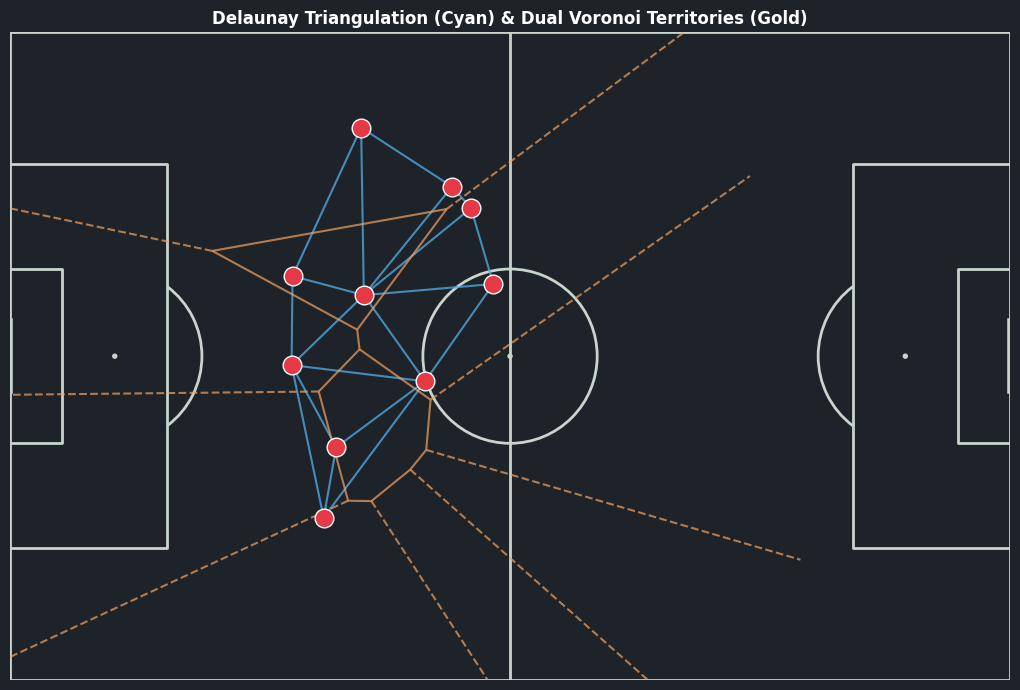

In [15]:
from scipy.spatial import Delaunay, Voronoi, voronoi_plot_2d
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# Using `pts` (your 10 outfield players in meters) from earlier
tri = Delaunay(pts)
vor = Voronoi(pts)

pitch = Pitch(pitch_type="custom", pitch_length=105, pitch_width=68,
              pitch_color="#1e2229", line_color="#c7d5cc")
fig, ax = pitch.draw(figsize=(11, 7))
fig.patch.set_facecolor("#1e2229")

# Plot Voronoi territories (dashed gold lines)
voronoi_plot_2d(vor, ax=ax, show_points=False, show_vertices=False,
                line_colors="#f4a261", line_width=1.5, line_alpha=0.7)

# Plot Delaunay mesh (solid cyan lines)
ax.triplot(pts[:, 0], 68 - pts[:, 1], tri.simplices, color="#4ea8de", lw=1.5, alpha=0.8)

# Plot players
pitch.scatter(pts[:, 0], 68 - pts[:, 1], s=180, color="#e63946", edgecolors="white", zorder=4, ax=ax)
ax.set_xlim(0, 105)
ax.set_ylim(0, 68)
ax.set_title("Delaunay Triangulation (Cyan) & Dual Voronoi Territories (Gold)", color="white", fontweight="bold")
plt.show()

In [17]:
import shutil
import numpy as np
import pandas as pd
from scipy.spatial import Delaunay
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mplsoccer import Pitch

PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
FRAME_RATE = 25

# ==========================================
# 1. Load Events & Find All Goals in the Match
# ==========================================
events_df = pd.read_csv("Game1event.csv")

goals = events_df[
    (events_df["Type"] == "SHOT") & 
    (events_df["Subtype"].str.contains("GOAL", case=False, na=False))
].reset_index(drop=True)

if len(goals) == 0:
    raise ValueError("No goals found in events_df!")

print(f"Found {len(goals)} goal(s) in the match. Exporting videos...")

# Choose MP4 if ffmpeg is installed, otherwise fallback to GIF
use_ffmpeg = shutil.which("ffmpeg") is not None
ext = "mp4" if use_ffmpeg else "gif"
writer = "ffmpeg" if use_ffmpeg else "pillow"

# ==========================================
# 2. Loop Through Every Goal & Save Video
# ==========================================
for goal_idx, goal_event in goals.iterrows():
    goal_frame = int(goal_event["Start Frame"])
    scoring_team = goal_event["Team"].lower()
    defending_team = "away" if scoring_team == "home" else "home"
    period_id = int(goal_event["Period"])
    
    # Extract 60s window before the goal (downsampled by 3 -> ~8.3 fps)
    start_frame = max(1, goal_frame - (60 * FRAME_RATE))
    window_df = df_tracking[
        (df_tracking["period_id"] == period_id) &
        (df_tracking["frame_id"] >= start_frame) &
        (df_tracking["frame_id"] <= goal_frame + 25)
    ].iloc[::3].copy().reset_index(drop=True)
    
    # Identify attacking outfield players (exclude GK) and defending players
    team_players = sorted({
        col[:-2] for col in df_tracking.columns 
        if col.startswith(f"{scoring_team}_") and col.endswith("_x")
    })
    def_players = sorted({
        col[:-2] for col in df_tracking.columns 
        if col.startswith(f"{defending_team}_") and col.endswith("_x")
    })
    
    p_means = {pid: window_df[f"{pid}_x"].mean() for pid in team_players if window_df[f"{pid}_x"].notna().any()}
    gk_id = min(p_means, key=lambda k: min(p_means[k], 1.0 - p_means[k]))
    outfield_players = [p for p in team_players if p != gk_id]
    
    # Set up pitch canvas
    pitch = Pitch(
        pitch_type="custom", pitch_length=PITCH_LENGTH, pitch_width=PITCH_WIDTH,
        pitch_color="#1e2229", line_color="#c7d5cc", linewidth=1.5
    )
    fig, ax = pitch.draw(figsize=(10, 6.2))
    fig.set_dpi(120 if use_ffmpeg else 80)
    fig.patch.set_facecolor("#1e2229")
    
    tri_lines = ax.plot([], [], color="#4ea8de", alpha=0.55, lw=1.5, zorder=2)[0]
    active_poly = ax.fill([], [], color="#f4a261", alpha=0.40, zorder=2)[0]
    att_scatter = ax.scatter([], [], s=210, color="#e63946", edgecolors="white", lw=1.5, zorder=4)
    def_scatter = ax.scatter([], [], s=150, color="#6c757d", edgecolors="#adb5bd", alpha=0.65, lw=1, zorder=3)
    ball_scatter = ax.scatter([], [], s=100, color="#ffd166", edgecolors="black", lw=1.5, zorder=5)
    
    jersey_texts = [
        ax.text(0, 0, "", color="white", fontsize=8.5, fontweight="bold", ha="center", va="center", zorder=5)
        for _ in range(11)
    ]
    title_text = ax.set_title("", color="white", fontsize=12, fontweight="bold", pad=10)
    
    def make_update_fn(w_df, out_p, def_p, g_frame, s_team, g_num):
        def update(frame_idx):
            row = w_df.iloc[frame_idx]
            
            pts, labels = [], []
            for pid in out_p:
                px, py = row[f"{pid}_x"], row[f"{pid}_y"]
                if pd.notna(px) and pd.notna(py):
                    pts.append([px * PITCH_LENGTH, PITCH_WIDTH - (py * PITCH_WIDTH)])
                    labels.append(pid.split("_")[1])
            pts = np.array(pts)
            
            def_pts = []
            for pid in def_p:
                px, py = row[f"{pid}_x"], row[f"{pid}_y"]
                if pd.notna(px) and pd.notna(py):
                    def_pts.append([px * PITCH_LENGTH, PITCH_WIDTH - (py * PITCH_WIDTH)])
            def_pts = np.array(def_pts)
            
            bx = row["ball_x"] * PITCH_LENGTH
            by = PITCH_WIDTH - (row["ball_y"] * PITCH_WIDTH)
            
            if len(pts) > 0:
                att_scatter.set_offsets(pts)
            if len(def_pts) > 0:
                def_scatter.set_offsets(def_pts)
            if pd.notna(bx) and pd.notna(by):
                ball_scatter.set_offsets([[bx, by]])
                
            for i, txt in enumerate(jersey_texts):
                if i < len(pts):
                    txt.set_position((pts[i, 0], pts[i, 1]))
                    txt.set_text(labels[i])
                else:
                    txt.set_text("")
                    
            active_tri_str = "Outside Convex Hull"
            if len(pts) >= 4:
                tri = Delaunay(pts)
                edges_x, edges_y = [], []
                for simplex in tri.simplices:
                    for i in range(3):
                        p1, p2 = pts[simplex[i]], pts[simplex[(i + 1) % 3]]
                        edges_x.extend([p1[0], p2[0], np.nan])
                        edges_y.extend([p1[1], p2[1], np.nan])
                tri_lines.set_data(edges_x, edges_y)
                
                if pd.notna(bx) and pd.notna(by):
                    s_idx = tri.find_simplex([bx, by])
                    if s_idx != -1:
                        verts = pts[tri.simplices[s_idx]]
                        active_poly.set_xy(verts)
                        tri_jerseys = sorted([labels[i] for i in tri.simplices[s_idx]])
                        active_tri_str = f"({' - '.join(tri_jerseys)})"
                    else:
                        active_poly.set_xy(np.empty((0, 2)))
                else:
                    active_poly.set_xy(np.empty((0, 2)))
                    
            secs_to_goal = (g_frame - row["frame_id"]) / FRAME_RATE
            clock_str = f"-{secs_to_goal:.1f}s to Goal" if secs_to_goal >= 0 else "GOAL!"
            title_text.set_text(
                f"Goal #{g_num} ({s_team.upper()} | {clock_str}) | Active Triangle: {active_tri_str}"
            )
        return update

    update_fn = make_update_fn(window_df, outfield_players, def_players, goal_frame, scoring_team, goal_idx + 1)
    update_fn(0)
    
    anim = FuncAnimation(fig, update_fn, frames=len(window_df), interval=120, blit=False)
    
    filename = f"goal_{goal_idx + 1}_{scoring_team}_period{period_id}_frame{goal_frame}.{ext}"
    anim.save(filename, writer=writer, fps=8)
    plt.close(fig)
    print(f"Saved: {filename}")

print("All goal animations exported successfully.")

Found 3 goal(s) in the match. Exporting videos...
Saved: goal_1_home_period1_frame2289.gif
Saved: goal_2_home_period2_frame90005.gif
Saved: goal_3_home_period2_frame99032.gif
All goal animations exported successfully.


# MASTER CODE

## GIVES DELANEY TRAINGULATION, VORONOI PITCH CONTROL BEFORE EVERY GOAL

In [18]:
import shutil
import numpy as np
import pandas as pd
from scipy.spatial import Delaunay, Voronoi
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mplsoccer import Pitch

# ==========================================
# CONFIGURATION PARAMETERS
# ==========================================
GOAL_NUMBER = 2          # 1 for 1st goal, 2 for 2nd goal, etc. (or "ALL" to export every goal)
SECONDS_BEFORE = 60      # Seconds of build-up before the goal
DOWNSAMPLE_STEP = 3      # 3 -> ~8.3 fps (fast export); 2 -> 12.5 fps (smoother)
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
FRAME_RATE = 25

# ==========================================
# 1. Load Events & Identify Goals
# ==========================================
events_df = pd.read_csv("Game1event.csv")

goals = events_df[
    (events_df["Type"] == "SHOT") & 
    (events_df["Subtype"].str.contains("GOAL", case=False, na=False))
].reset_index(drop=True)

if len(goals) == 0:
    raise ValueError("No goals found in events_df!")

print(f"Total goals in match: {len(goals)}")
for idx, g in goals.iterrows():
    print(f"  Goal #{idx + 1}: {g['Team']} at Frame {int(g['Start Frame'])} (Period {int(g['Period'])})")

# Select target goal(s)
if GOAL_NUMBER == "ALL":
    target_indices = list(range(len(goals)))
elif isinstance(GOAL_NUMBER, int) and 1 <= GOAL_NUMBER <= len(goals):
    target_indices = [GOAL_NUMBER - 1]
else:
    raise ValueError(f"Invalid GOAL_NUMBER={GOAL_NUMBER}. Choose an integer between 1 and {len(goals)}, or 'ALL'.")

# Video writer setup (MP4 if ffmpeg is installed, otherwise GIF)
use_ffmpeg = shutil.which("ffmpeg") is not None
ext = "mp4" if use_ffmpeg else "gif"
writer = "ffmpeg" if use_ffmpeg else "pillow"

# ==========================================
# 2. Helper Function: Compute Finite Voronoi Segments
# ==========================================
def get_voronoi_segments(pts, pitch_len=105.0, pitch_wid=68.0):
    """
    Computes finite line segments (x_coords, y_coords) for a 2D Voronoi diagram
    clipped cleanly to pitch boundaries, including infinite outer ridges.
    """
    if len(pts) < 4:
        return [], []
        
    vor = Voronoi(pts)
    center = pts.mean(axis=0)
    radius = max(pitch_len, pitch_wid) * 2.0
    
    vx, vy = [], []
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        if v1 >= 0 and v2 >= 0:
            # Finite ridge between two Voronoi vertices
            pt1, pt2 = vor.vertices[v1], vor.vertices[v2]
            vx.extend([pt1[0], pt2[0], np.nan])
            vy.extend([pt1[1], pt2[1], np.nan])
        else:
            # Infinite ridge: project outward perpendicular to the line between p1 and p2
            v_finite = v1 if v1 >= 0 else v2
            tangent = pts[p2] - pts[p1]
            tangent /= np.linalg.norm(tangent)
            normal = np.array([-tangent[1], tangent[0]])
            
            midpoint = pts[[p1, p2]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, normal)) * normal
            far_point = vor.vertices[v_finite] + direction * radius
            
            vx.extend([vor.vertices[v_finite][0], far_point[0], np.nan])
            vy.extend([vor.vertices[v_finite][1], far_point[1], np.nan])
            
    return vx, vy

# ==========================================
# 3. Animate & Export Selected Goal(s)
# ==========================================
for goal_idx in target_indices:
    goal_event = goals.iloc[goal_idx]
    goal_frame = int(goal_event["Start Frame"])
    scoring_team = goal_event["Team"].lower()
    defending_team = "away" if scoring_team == "home" else "home"
    period_id = int(goal_event["Period"])
    
    print(f"\nRendering Goal #{goal_idx + 1} ({scoring_team.upper()}, Period {period_id}, Frame {goal_frame})...")
    
    start_frame = max(1, goal_frame - (SECONDS_BEFORE * FRAME_RATE))
    window_df = df_tracking[
        (df_tracking["period_id"] == period_id) &
        (df_tracking["frame_id"] >= start_frame) &
        (df_tracking["frame_id"] <= goal_frame + 25)
    ].iloc[::DOWNSAMPLE_STEP].copy().reset_index(drop=True)
    
    team_players = sorted({
        col[:-2] for col in df_tracking.columns 
        if col.startswith(f"{scoring_team}_") and col.endswith("_x")
    })
    def_players = sorted({
        col[:-2] for col in df_tracking.columns 
        if col.startswith(f"{defending_team}_") and col.endswith("_x")
    })
    
    # Exclude Goalkeeper of scoring team from outfield triangulation/Voronoi
    p_means = {pid: window_df[f"{pid}_x"].mean() for pid in team_players if window_df[f"{pid}_x"].notna().any()}
    gk_id = min(p_means, key=lambda k: min(p_means[k], 1.0 - p_means[k]))
    outfield_players = [p for p in team_players if p != gk_id]
    
    # Set up Pitch Canvas
    pitch = Pitch(
        pitch_type="custom", pitch_length=PITCH_LENGTH, pitch_width=PITCH_WIDTH,
        pitch_color="#1e2229", line_color="#c7d5cc", linewidth=1.5
    )
    fig, ax = pitch.draw(figsize=(11, 6.8))
    fig.set_dpi(120 if use_ffmpeg else 85)
    fig.patch.set_facecolor("#1e2229")
    
    # Artists: Voronoi (dashed amber), Delaunay (solid cyan), Active Triangle (gold fill)
    vor_lines = ax.plot([], [], color="#f4a261", linestyle="--", alpha=0.65, lw=1.3, zorder=2, label="Voronoi Space Control")[0]
    tri_lines = ax.plot([], [], color="#4ea8de", linestyle="-", alpha=0.60, lw=1.5, zorder=3, label="Delaunay Passing Mesh")[0]
    active_poly = ax.fill([], [], color="#ffd166", alpha=0.32, zorder=2)[0]
    
    att_scatter = ax.scatter([], [], s=220, color="#e63946", edgecolors="white", lw=1.5, zorder=5, label=f"{scoring_team.capitalize()} Outfield")
    def_scatter = ax.scatter([], [], s=150, color="#6c757d", edgecolors="#adb5bd", alpha=0.65, lw=1, zorder=4, label=f"{defending_team.capitalize()} Defenders")
    ball_scatter = ax.scatter([], [], s=100, color="#ffd166", edgecolors="black", lw=1.5, zorder=6, label="Ball")
    
    jersey_texts = [
        ax.text(0, 0, "", color="white", fontsize=8.5, fontweight="bold", ha="center", va="center", zorder=6)
        for _ in range(11)
    ]
    title_text = ax.set_title("", color="white", fontsize=11.5, fontweight="bold", pad=12)
    
    # Legend in upper-left outside/along top edge
    ax.legend(
        loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=5,
        frameon=False, labelcolor="white", fontsize=9
    )
    
    def make_update_fn(w_df, out_p, def_p, g_frame, s_team, g_num):
        def update(frame_idx):
            row = w_df.iloc[frame_idx]
            
            pts, labels = [], []
            for pid in out_p:
                px, py = row[f"{pid}_x"], row[f"{pid}_y"]
                if pd.notna(px) and pd.notna(py):
                    pts.append([px * PITCH_LENGTH, PITCH_WIDTH - (py * PITCH_WIDTH)])
                    labels.append(pid.split("_")[1])
            pts = np.array(pts)
            
            def_pts = []
            for pid in def_p:
                px, py = row[f"{pid}_x"], row[f"{pid}_y"]
                if pd.notna(px) and pd.notna(py):
                    def_pts.append([px * PITCH_LENGTH, PITCH_WIDTH - (py * PITCH_WIDTH)])
            def_pts = np.array(def_pts)
            
            bx = row["ball_x"] * PITCH_LENGTH
            by = PITCH_WIDTH - (row["ball_y"] * PITCH_WIDTH)
            
            if len(pts) > 0:
                att_scatter.set_offsets(pts)
            if len(def_pts) > 0:
                def_scatter.set_offsets(def_pts)
            if pd.notna(bx) and pd.notna(by):
                ball_scatter.set_offsets([[bx, by]])
                
            for i, txt in enumerate(jersey_texts):
                if i < len(pts):
                    txt.set_position((pts[i, 0], pts[i, 1]))
                    txt.set_text(labels[i])
                else:
                    txt.set_text("")
                    
            active_tri_str = "Outside Convex Hull"
            if len(pts) >= 4:
                # 1. Update Voronoi Diagram (dashed amber ridges)
                vx, vy = get_voronoi_segments(pts, PITCH_LENGTH, PITCH_WIDTH)
                vor_lines.set_data(vx, vy)
                
                # 2. Update Delaunay Triangulation (solid cyan edges)
                tri = Delaunay(pts)
                edges_x, edges_y = [], []
                for simplex in tri.simplices:
                    for i in range(3):
                        p1, p2 = pts[simplex[i]], pts[simplex[(i + 1) % 3]]
                        edges_x.extend([p1[0], p2[0], np.nan])
                        edges_y.extend([p1[1], p2[1], np.nan])
                tri_lines.set_data(edges_x, edges_y)
                
                # 3. Highlight Active Ball-Enclosing Triangle
                if pd.notna(bx) and pd.notna(by):
                    s_idx = tri.find_simplex([bx, by])
                    if s_idx != -1:
                        verts = pts[tri.simplices[s_idx]]
                        active_poly.set_xy(verts)
                        tri_jerseys = sorted([labels[i] for i in tri.simplices[s_idx]])
                        active_tri_str = f"({' - '.join(tri_jerseys)})"
                    else:
                        active_poly.set_xy(np.empty((0, 2)))
                else:
                    active_poly.set_xy(np.empty((0, 2)))
                    
            secs_to_goal = (g_frame - row["frame_id"]) / FRAME_RATE
            clock_str = f"-{secs_to_goal:.1f}s to Goal" if secs_to_goal >= 0 else "GOAL!"
            title_text.set_text(
                f"Goal #{g_num} ({s_team.upper()} | {clock_str}) | Active Triangle: {active_tri_str}"
            )
        return update

    update_fn = make_update_fn(window_df, outfield_players, def_players, goal_frame, scoring_team, goal_idx + 1)
    update_fn(0)
    
    fps_out = max(1, int(FRAME_RATE / DOWNSAMPLE_STEP))
    anim = FuncAnimation(fig, update_fn, frames=len(window_df), interval=int(1000 / fps_out), blit=False)
    
    filename = f"goal_{goal_idx + 1}_{scoring_team}_del_vor_p{period_id}_f{goal_frame}.{ext}"
    anim.save(filename, writer=writer, fps=fps_out)
    plt.close(fig)
    print(f"Saved: {filename}")

print("\nDone!")

Total goals in match: 3
  Goal #1: Home at Frame 2289 (Period 1)
  Goal #2: Home at Frame 90005 (Period 2)
  Goal #3: Home at Frame 99032 (Period 2)

Rendering Goal #2 (HOME, Period 2, Frame 90005)...
Saved: goal_2_home_del_vor_p2_f90005.gif

Done!
